# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [114]:
# Replace None with your code
# Imports
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create connection to database
conn = sqlite3.connect ('data.sqlite')

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [115]:
# Replace None with your code
# creditLimit is stored as text, so CAST turns it into a number before comparing.
# Without CAST, text comparison would give wrong answers (e.g. '9000' > '25000').
df_california =pd.read_sql_query( """
SELECT customerNumber, customerName, contactFirstName, contactLastName,
       phone, city, state, country, creditLimit
FROM customers
WHERE state = 'CA'
  AND country = 'USA'
  AND CAST(creditLimit AS REAL) > 25000
ORDER BY CAST(creditLimit AS REAL) DESC;
""", conn)
   
df_california                           # 10 customers

,customerNumber,customerName,contactFirstName,contactLastName,phone,city,state,country,creditLimit
0,124,Mini Gifts Distributors Ltd.,Susan,Nelson,4155551450,San Rafael,CA,USA,210500.00
1,239,Collectable Mini Designs Co.,Valarie,Thompson,7605558146,San Diego,CA,USA,105000.00
2,321,Corporate Gift Ideas Co.,Julie,Brown,6505551386,San Francisco,CA,USA,105000.00
3,205,Toys4GrownUps.com,Julie,Young,6265557265,Pasadena,CA,USA,90700.00
4,161,Technics Stores Inc.,Juri,Hashimoto,6505556809,Burlingame,CA,USA,84600.00
5,450,The Sharp Gifts Warehouse,Sue,Frick,4085553659,San Jose,CA,USA,77600.00
6,129,Mini Wheels Co.,Julie,Murphy,6505555787,San Francisco,CA,USA,64600.00
7,487,Signal Collectibles Ltd.,Sue,Taylor,4155554312,Brisbane,CA,USA,60300.00
8,347,"Men 'R' US Retailers, Ltd.",Brian,Chandler,2155554369,Los Angeles,CA,USA,57700.00
9,475,West Coast Collectables Co.,Steve,Thompson,3105553722,Burbank,CA,USA,55400.00


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [116]:
# Replace None with your code
# != 'USA' keeps only non-US customers.
# LIKE '%Collect%' matches "Collect" anywhere in the name (% = any characters).
df_international_collect_customers = pd.read_sql_query("""
SELECT customerNumber, customerName, contactFirstName, contactLastName,
       city, country
FROM customers
WHERE country != 'USA'
  AND customerName LIKE '%Collect%'
ORDER BY country;
""",conn)

df_international_collect_customers                            

,customerNumber,customerName,contactFirstName,contactLastName,city,country
0,114,"Australian Collectors, Co.",Peter,Ferguson,Melbourne,Australia
1,471,"Australian Collectables, Ltd",Sean,Clenahan,Glen Waverly,Australia
2,382,Salzburg Collectables,Georg,Pipps,Salzburg,Austria
3,260,"Royal Canadian Collectables, Ltd.",Elizabeth,Lincoln,Tsawassen,Canada
4,227,Heintze Collectables,Palle,Ibsen,Århus,Denmark
5,353,Reims Collectables,Paul,Henriot,Reims,France
6,409,Stuttgart Collectable Exchange,Rita,Müller,Stuttgart,Germany
7,415,"Bavarian Collectables Imports, Co.",Michael,Donnermeyer,Munich,Germany
8,211,"King Kong Collectables, Co.",Mike,Gao,Central Hong Kong,Hong Kong
9,189,"Clover Collections, Co.",Dean,Cassidy,Dublin,Ireland


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!

WHERE in my query contains two expressions which are connected by ‘AND’. Consequently, only if both expressions are satisfied can a customer be selected. First of all, country != 'USA' excludes all customers from USA, leaving only those who belong to foreign countries. The second condition is that customerName LIKE '%Collect%', which means checking if “Collect” exists somewhere in the customer’s name. The signs “%” represent that the expression is “any number of characters in that location,” hence the names such as “Australian Collectors,” “Reims Collectables” and “Clover Collections” are returned. Since both conditions must be met, an American company with “Collect” in its name is omitted, and so is an international company without “Collect” in its name. This ensures that only the requested customers are returned.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [117]:
# Replace None with your code
# GROUP BY makes one row per state; AVG() averages the credit limits inside each state.
average_credit_by_state = pd.read_sql_query( """
SELECT state,
       COUNT(*) AS number_of_customers,
       ROUND(AVG(CAST(creditLimit AS REAL)), 2) AS average_credit_limit
FROM customers
WHERE country = 'USA'
    AND state IS NOT NULL
GROUP BY state
ORDER BY average_credit_limit DESC;
""",conn)

average_credit_by_state

,state,number_of_customers,average_credit_limit
0,NH,1,114200.00
1,NY,6,89966.67
2,PA,3,84766.67
3,CA,11,83854.55
4,NV,1,71800.00
5,MA,9,70755.56
6,CT,4,57350.00
7,NJ,1,43000.00


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

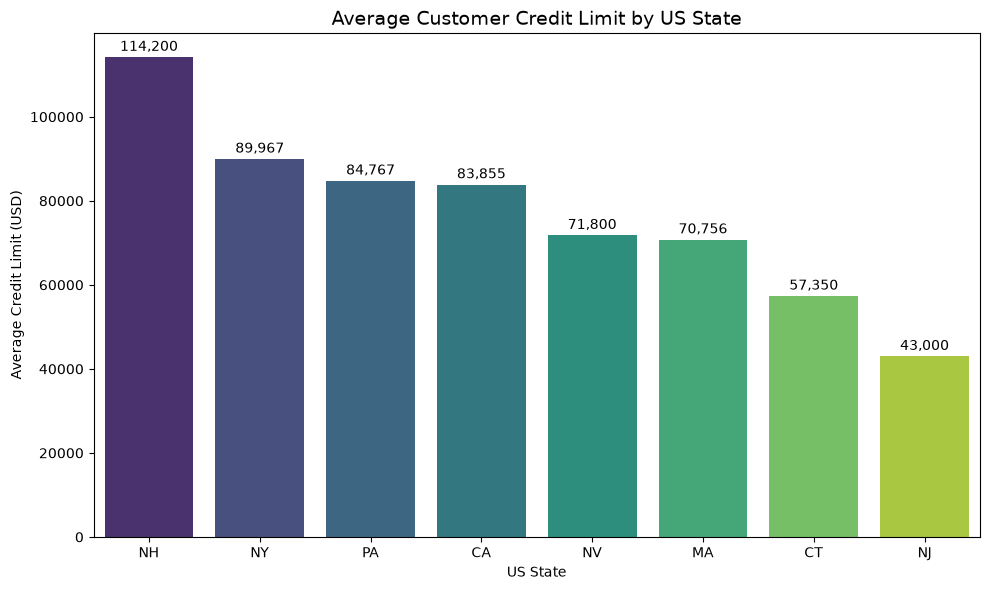

In [118]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
plt.figure(figsize=(10, 6))
sns.barplot(data=average_credit_by_state, 
            x='state', 
            y='average_credit_limit', 
            hue = 'state',
            palette='viridis',
            legend= False)

plt.title('Average Customer Credit Limit by US State', fontsize=14)
plt.xlabel('US State')
plt.ylabel('Average Credit Limit (USD)')

# Write the value above each bar
for i, value in enumerate(average_credit_by_state['average_credit_limit']):
    plt.text(i, value + 1500, f'{value:,.0f}', ha='center')

plt.tight_layout()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [119]:
# Replace None with your code
# JOIN links each customer to their payments through customerNumber.
# SUM adds up all payments per customer; LIMIT 10 keeps the top 10.
top_10_customers= pd.read_sql_query("""
SELECT c.customerNumber,
       c.customerName,
       ROUND(SUM(CAST(p.amount AS REAL)), 2) AS total_payments
FROM customers c
JOIN payments p ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber, c.customerName
ORDER BY total_payments DESC
LIMIT 10;
""",conn)

top_10_customers

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

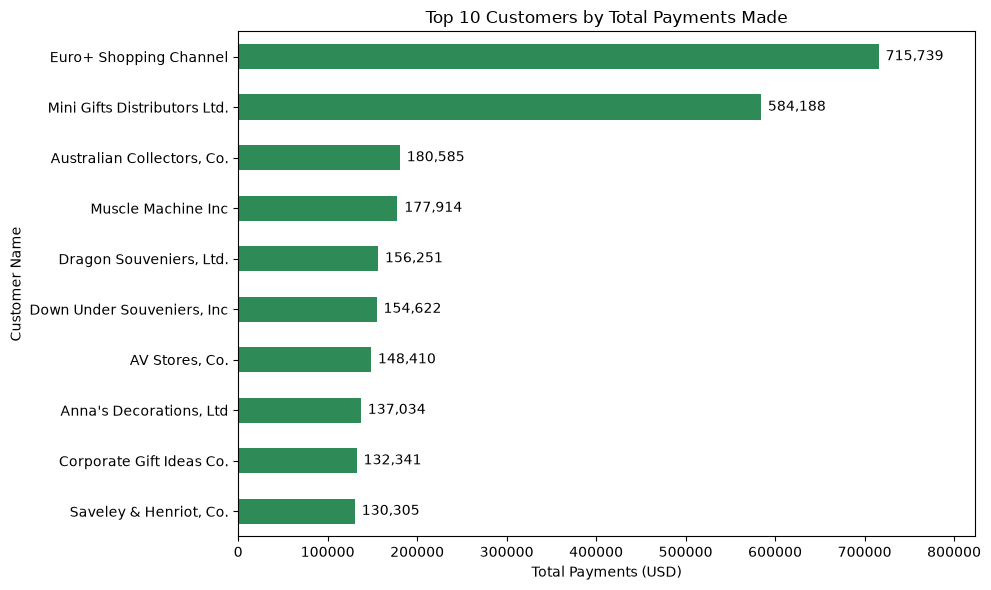

In [120]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments

# Sort so the largest customer appears at the top of the horizontal chart
ax = top_10_customers.sort_values("total_payments").plot(
    kind="barh",
    x="customerName",
    y="total_payments",
    legend=False,
    figsize=(10, 6),
    color="seagreen"                       # sets a colour for the bars
)

# Verbose title and axis labels
plt.title("Top 10 Customers by Total Payments Made")
plt.xlabel("Total Payments (USD)")         # includes the unit
plt.ylabel("Customer Name")

# Write the exact total at the end of each bar
for bar in ax.patches:
    ax.annotate(f"{bar.get_width():,.0f}",
                (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                ha="left", va="center",
                xytext=(5, 0), textcoords="offset points")

# Add room on the right so the longest label isn't cut off
ax.set_xlim(0, top_10_customers["total_payments"].max() * 1.15)

plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [121]:
# Replace None with you code
# Order of clauses matters: JOIN -> GROUP BY -> HAVING -> ORDER BY.
# HAVING filters AFTER grouping (WHERE can't filter on SUM).
customer_product_quantities = pd.read_sql_query( """
SELECT c.customerNumber,
       c.customerName,
       pr.productCode,
       pr.productName,
       SUM(CAST(od.quantityOrdered AS INTEGER)) AS total_quantity
FROM customers c
JOIN orders o        ON c.customerNumber = o.customerNumber
JOIN orderdetails od ON o.orderNumber   = od.orderNumber
JOIN products pr     ON od.productCode  = pr.productCode
GROUP BY c.customerNumber, c.customerName, pr.productCode, pr.productName
HAVING SUM(CAST(od.quantityOrdered AS INTEGER)) >= 10
ORDER BY total_quantity ASC;
""",conn)
customer_product_quantities

,customerNumber,customerName,productCode,productName,total_quantity
0,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
1,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [122]:
# Replace None with your code
# COUNT(DISTINCT productCode) counts each product once. A plain COUNT would
# count a product once per order line and inflate the number (duplicates).
product_line_summary = pd.read_sql_query("""
SELECT pl.productLine,
       COUNT(DISTINCT p.productCode) AS number_of_products,
       SUM(CAST(od.quantityOrdered AS INTEGER)) AS total_quantity_ordered
FROM productlines pl
JOIN products p      ON pl.productLine = p.productLine
JOIN orderdetails od ON p.productCode  = od.productCode
GROUP BY pl.productLine
ORDER BY total_quantity_ordered DESC;
""",conn)

product_line_summary

,productLine,number_of_products,total_quantity_ordered
0,Classic Cars,37,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

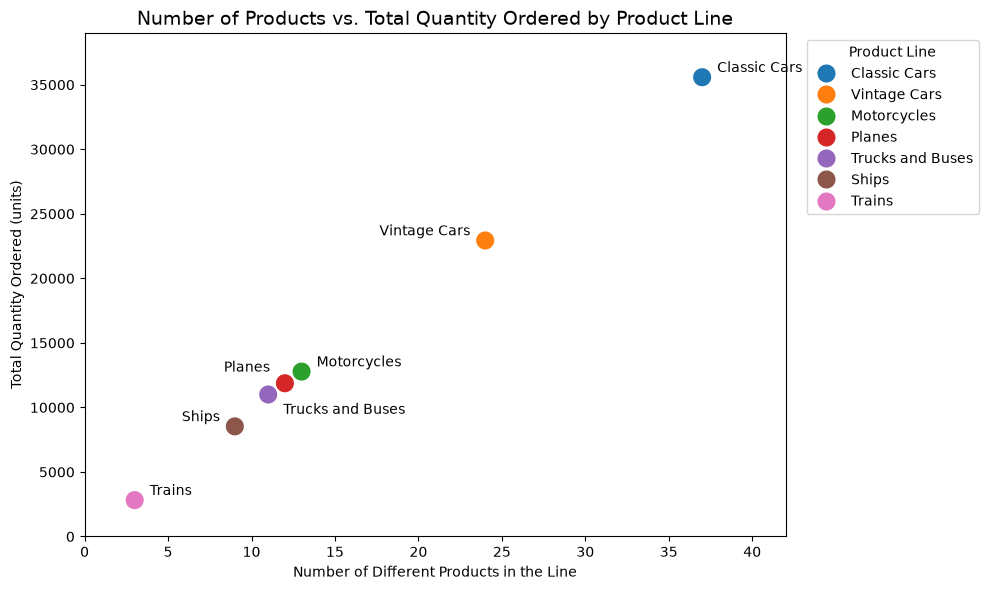

In [123]:
# Replace None with your visual code
# Produce a visual to represent the relation between number of products and the total amount ordered

# Scatter plot, because we compare TWO numbers (products vs. quantity ordered)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=product_line_summary,
    x='number_of_products',
    y='total_quantity_ordered',
    hue='productLine',        # a different colour for each product line
    s=200                     # dot size
)

# Where each label sits next to its dot: (shift left/right, shift up/down, text alignment)
# These are set by hand because Motorcycles, Planes and Trucks and Buses are close together
label_positions = {
    'Classic Cars':     (0.9, 400, 'left'),
    'Vintage Cars':     (-0.9, 400, 'right'),
    'Motorcycles':      (0.9, 400, 'left'),
    'Planes':           (-0.9, 900, 'right'),
    'Trucks and Buses': (0.9, -1500, 'left'),
    'Ships':            (-0.9, 400, 'right'),
    'Trains':           (0.9, 400, 'left'),
}

# Write each product line's name next to its dot
for _, row in product_line_summary.iterrows():
    x_shift, y_shift, align = label_positions[row['productLine']]
    plt.text(row['number_of_products'] + x_shift,
             row['total_quantity_ordered'] + y_shift,
             row['productLine'],
             ha=align)

# Verbose title and axis labels
plt.title('Number of Products vs. Total Quantity Ordered by Product Line', fontsize=14)
plt.xlabel('Number of Different Products in the Line')
plt.ylabel('Total Quantity Ordered (units)')

# Extra room on the right and top so no label is cut off
plt.xlim(0, 42)
plt.ylim(0, 39000)

# Legend outside the plot, so it doesn't cover any dots
plt.legend(title='Product Line', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!

I used a scatter plot because I wanted to compare two numbers for each product line at the same time: how many products it has and how many units customers ordered. Each dot on the chart is one product line, so it's easy to see whether the two numbers go up together. The dots go from the bottom left to the top right. Classic Cars is at the top right, with the most products (37) and the most units ordered (about 35,600). Trains is at the bottom left, with the fewest products (3) and the fewest units ordered (about 2,800). So, for the question we were asked, it looks like product lines with more products usually get more orders. But this is just a first look. It doesn't prove that adding more products will cause more sales.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [124]:
# Replace None with your code
# The inner query (subquery) finds office codes with fewer than 5 employees.
# The outer query returns employees whose officeCode is in that list.
# A self-join (employees s) looks up each employee's supervisor by name.
employees_in_small_offices = pd.read_sql_query( """
SELECT e.employeeNumber, e.firstName, e.lastName, e.jobTitle, e.email,
       e.officeCode, o.city AS office_city, o.country AS office_country,
       e.reportsTo AS supervisor_number,
       s.firstName AS supervisor_first_name,
       s.lastName  AS supervisor_last_name
FROM employees e
JOIN offices o ON e.officeCode = o.officeCode
LEFT JOIN employees s ON e.reportsTo = s.employeeNumber
WHERE e.officeCode IN (
    SELECT officeCode
    FROM employees
    GROUP BY officeCode
    HAVING COUNT(*) < 5
)
ORDER BY o.city,e.lastName,e.firstName
""",conn)

employees_in_small_offices

,employeeNumber,firstName,lastName,jobTitle,email,officeCode,office_city,office_country,supervisor_number,supervisor_first_name,supervisor_last_name
0,1188,Julie,Firrelli,Sales Rep,jfirrelli@classicmodelcars.com,2,Boston,USA,1143,Anthony,Bow
1,1216,Steve,Patterson,Sales Rep,spatterson@classicmodelcars.com,2,Boston,USA,1143,Anthony,Bow
2,1501,Larry,Bott,Sales Rep,lbott@classicmodelcars.com,7,London,UK,1102,Gerard,Bondur
3,1504,Barry,Jones,Sales Rep,bjones@classicmodelcars.com,7,London,UK,1102,Gerard,Bondur
4,1286,Foon Yue,Tseng,Sales Rep,ftseng@classicmodelcars.com,3,NYC,USA,1143,Anthony,Bow
5,1323,George,Vanauf,Sales Rep,gvanauf@classicmodelcars.com,3,NYC,USA,1143,Anthony,Bow
6,1611,Andy,Fixter,Sales Rep,afixter@classicmodelcars.com,6,Sydney,Australia,1088,William,Patterson
7,1619,Tom,King,Sales Rep,tking@classicmodelcars.com,6,Sydney,Australia,1088,William,Patterson
8,1612,Peter,Marsh,Sales Rep,pmarsh@classicmodelcars.com,6,Sydney,Australia,1088,William,Patterson
9,1088,William,Patterson,Sales Manager (APAC),wpatterson@classicmodelcars.com,6,Sydney,Australia,1056,Mary,Patterson


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!

The question has two parts: 1) Identify which offices are small; 2) Identify who works in those small offices. The first part is done by the subquery. It groups the employees table by officeCode and only includes the offices that have fewer than 5 employees in them by using HAVING COUNT(*) < 5. I used HAVING because the count only exists after the GROUP BY. WHERE officeCode IN (subquery) is then used in the main query to return only employees working in the offices found by the subquery. Instead of entering the office codes manually, I used a subquery, so the result stays correct automatically if staffing changes. I joined the offices table to show each employee’s location, and I joined the employees table to itself, using reportsTo, to display each supervisor’s name.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [125]:
# Replace None with your code
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [126]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

# Begin your code here


List the tables, their sizes and columns

In [127]:
# Loop through every table: count its rows and list its column names
table_names = ['movie_basics', 'movie_ratings', 'movie_akas', 'persons',
               'principals', 'directors', 'writers', 'known_for']
overview = []

for table in table_names:
    row_count = pd.read_sql(f"SELECT COUNT(*) AS n FROM {table};", conn4)['n'][0]
    columns = pd.read_sql(f"PRAGMA table_info({table});", conn4)['name'].tolist()
    overview.append({'table': table, 'rows': row_count, 'columns': ', '.join(columns)})

table_overview = pd.DataFrame(overview)
table_overview

,table,rows,columns
0,movie_basics,146144,"movie_id, primary_title, original_title, start..."
1,movie_ratings,73856,"movie_id, averagerating, numvotes"
2,movie_akas,331703,"movie_id, ordering, title, region, language, t..."
3,persons,606648,"person_id, primary_name, birth_year, death_yea..."
4,principals,1028186,"movie_id, ordering, person_id, category, job, ..."
5,directors,291174,"movie_id, person_id"
6,writers,255873,"movie_id, person_id"
7,known_for,1638260,"person_id, movie_id"


Preview the main tables

In [128]:
# movie_basics: one row per movie (title, year, runtime, genres)
movie_basics_preview = pd.read_sql("SELECT * FROM movie_basics LIMIT 5;", conn4)
movie_basics_preview

,movie_id,primary_title,original_title,start_year,runtime_minutes,genres
0,tt0063540,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama"
1,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,"Biography,Drama"
2,tt0069049,The Other Side of the Wind,The Other Side of the Wind,2018,122.0,Drama
3,tt0069204,Sabse Bada Sukh,Sabse Bada Sukh,2018,NaN,"Comedy,Drama"
4,tt0100275,The Wandering Soap Opera,La Telenovela Errante,2017,80.0,"Comedy,Drama,Fantasy"


In [129]:
# movie_ratings: average rating and number of votes, linked by movie_id
movie_ratings_preview = pd.read_sql("SELECT * FROM movie_ratings LIMIT 5;", conn4)
movie_ratings_preview

,movie_id,averagerating,numvotes
0,tt10356526,8.3,31
1,tt10384606,8.9,559
2,tt1042974,6.4,20
3,tt1043726,4.2,50352
4,tt1060240,6.5,21


Checking data types, missing values and ranges

In [130]:
# Load movie_basics into a DataFrame so we can use Pandas summary tools
movie_basics_df = pd.read_sql("SELECT * FROM movie_basics;", conn4)

# Data type of each column
movie_basics_df.dtypes

movie_id               str
primary_title          str
original_title         str
start_year           int64
runtime_minutes    float64
genres                 str
dtype: object

In [131]:
# Number of missing values in each column
movie_basics_df.isnull().sum()

movie_id               0
primary_title          0
original_title        21
start_year             0
runtime_minutes    31739
genres              5408
dtype: int64

In [132]:
# Smallest, largest and typical values for the number columns
movie_basics_df.describe()

,start_year,runtime_minutes
count,146144.000000,114405.000000
mean,2014.621798,86.187247
std,2.733583,166.360590
min,2010.000000,1.000000
25%,2012.000000,70.000000
50%,2015.000000,87.000000
75%,2017.000000,99.000000
max,2115.000000,51420.000000


Scope of the data

In [133]:
# How big is the database, and how many movies fall in 2010-2019?
# SUM(condition) counts the rows where the condition is true.
scope = pd.read_sql("""
SELECT COUNT(*) AS total_titles,
       SUM(start_year BETWEEN 2010 AND 2019) AS titles_2010_to_2019
FROM movie_basics;
""", conn4)
scope
# Result: 146,144 titles in total; 145,081 are from 2010-2019

,total_titles,titles_2010_to_2019
0,146144,145081


Movies per year


In [134]:
# Instructions say to ignore anything after 2019, so every query filters on start_year
movies_per_year = pd.read_sql("""
SELECT start_year, COUNT(*) AS number_of_movies
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019
GROUP BY start_year
ORDER BY start_year;
""", conn4)
movies_per_year


,start_year,number_of_movies
0,2010,11849
1,2011,12900
2,2012,13787
3,2013,14709
4,2014,15589
5,2015,16243
6,2016,17272
7,2017,17504
8,2018,16849
9,2019,8379


A visual

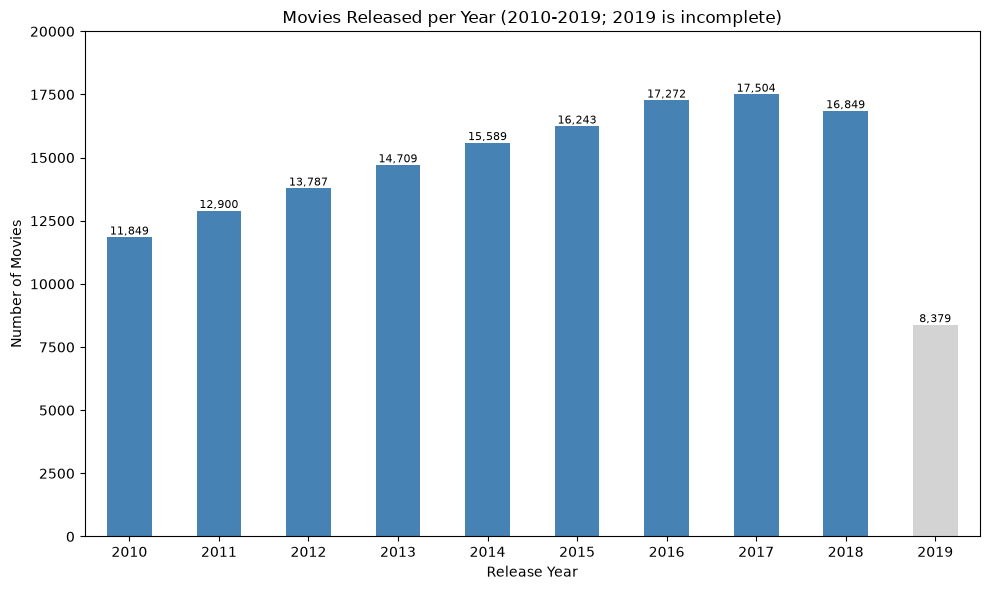

In [135]:
# The 2019 bar is grey to show that year looks incomplete
bar_colors = ['steelblue' if y != 2019 else 'lightgray' for y in movies_per_year['start_year']]

ax = movies_per_year.plot(kind='bar', 
                          x='start_year', 
                          y='number_of_movies',
                          legend=False, 
                          figsize=(10, 6), 
                          color=bar_colors)

plt.title('Movies Released per Year (2010-2019; 2019 is incomplete)')
plt.xlabel('Release Year')
plt.ylabel('Number of Movies')
plt.xticks(rotation=0)
plt.ylim(0, 20000)

# Write the value on top of each bar
ax.bar_label(ax.containers[0],
             labels=[f"{v:,}" for v in movies_per_year['number_of_movies']], fontsize=8)

plt.tight_layout()
plt.savefig('visual1_movies_per_year.png', dpi=200, bbox_inches='tight')
plt.show()

Missing values(we only count them, we don't fill them in)

In [136]:
missing_values = pd.read_sql("""
SELECT COUNT(*) AS movies,
       SUM(runtime_minutes IS NULL) AS missing_runtime,
       SUM(genres IS NULL) AS missing_genres
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019;
""", conn4)
missing_values


,movies,missing_runtime,missing_genres
0,145081,30765,5359


A visual

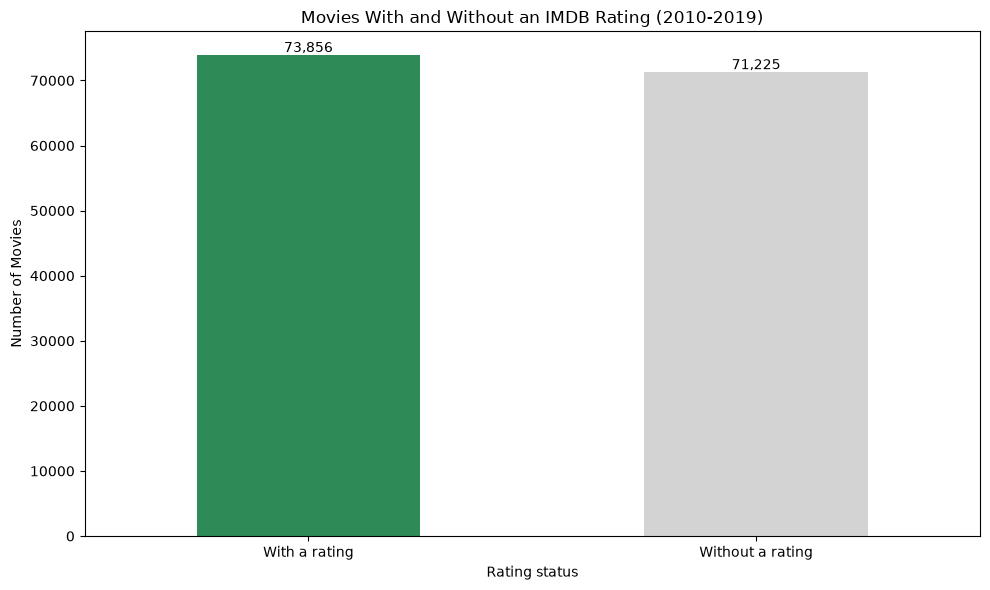

In [137]:
rated_counts = pd.read_sql("""
SELECT (SELECT COUNT(*) FROM movie_basics
        WHERE start_year BETWEEN 2010 AND 2019) AS all_movies,
       (SELECT COUNT(*) FROM movie_basics b
        JOIN movie_ratings r ON b.movie_id = r.movie_id
        WHERE b.start_year BETWEEN 2010 AND 2019) AS rated_movies;
""", conn4)

rating_status = pd.DataFrame({
    'Rating status': ['With a rating', 'Without a rating'],
    'Number of movies': [rated_counts['rated_movies'][0],
                         rated_counts['all_movies'][0] - rated_counts['rated_movies'][0]]
})

ax = rating_status.plot(kind='bar', x='Rating status', y='Number of movies',
                        legend=False, figsize=(10, 6), color=['seagreen', 'lightgray'])

plt.title('Movies With and Without an IMDB Rating (2010-2019)')
plt.xlabel('Rating status')
plt.ylabel('Number of Movies')
plt.xticks(rotation=0)

for bar in ax.patches:
    ax.annotate(f"{bar.get_height():,.0f}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom')

plt.tight_layout()
plt.savefig('visual2_rated_vs_unrated.png', dpi=200, bbox_inches='tight')
plt.show()

4.Which genres are rated highest and lowest?

In [138]:
# JOIN links each movie to its rating. IS NOT NULL leaves out missing values.
# HAVING keeps only genre combinations with 100+ movies so the averages are reliable.
genre_ratings = pd.read_sql("""
SELECT b.genres,
       COUNT(*) AS number_of_movies,
       ROUND(AVG(r.averagerating), 2) AS avg_rating,
       ROUND(AVG(b.runtime_minutes), 1) AS avg_runtime
FROM movie_basics b
JOIN movie_ratings r ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND b.genres IS NOT NULL
  AND b.runtime_minutes IS NOT NULL
GROUP BY b.genres
HAVING COUNT(*) >= 100
ORDER BY avg_rating DESC;
""", conn4)
genre_ratings.head(5)   

,genres,number_of_movies,avg_rating,avg_runtime
0,"Biography,Documentary,Music",235,7.57,89.8
1,"Adventure,Documentary",126,7.56,77.5
2,Music,136,7.55,102.2
3,"Biography,Documentary,Family",132,7.54,79.5
4,"Biography,Documentary,Drama",374,7.50,80.4


In [139]:
genre_ratings.tail(5)   # bottom five

,genres,number_of_movies,avg_rating,avg_runtime
87,"Horror,Mystery,Thriller",364,5.05,89.6
88,"Horror,Thriller",943,4.75,88.9
89,Horror,2232,4.69,85.8
90,"Horror,Sci-Fi,Thriller",109,4.68,90.8
91,"Action,Horror,Thriller",103,4.33,91.6


A visual

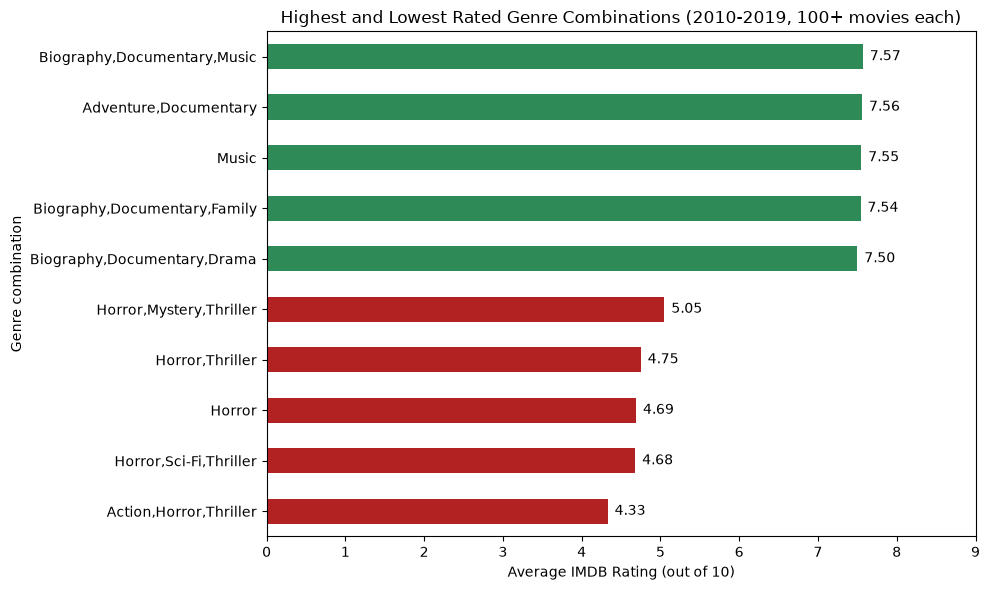

In [140]:
# Take the 5 best and 5 worst genre combinations from the genre_ratings table
top_and_bottom = pd.concat([genre_ratings.head(5), genre_ratings.tail(5)])
top_and_bottom = top_and_bottom.sort_values('avg_rating')

# The first 5 rows are the lowest rated (red), the last 5 the highest (green)
bar_colors = ['firebrick'] * 5 + ['seagreen'] * 5

ax = top_and_bottom.plot(kind='barh', x='genres', y='avg_rating',
                         legend=False, figsize=(10, 6), color=bar_colors)

plt.title('Highest and Lowest Rated Genre Combinations (2010-2019, 100+ movies each)')
plt.xlabel('Average IMDB Rating (out of 10)')
plt.ylabel('Genre combination')
plt.xlim(0, 9)

for bar in ax.patches:
    ax.annotate(f"{bar.get_width():.2f}", (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                ha='left', va='center', xytext=(5, 0), textcoords='offset points')

plt.tight_layout()
plt.savefig('visual3_top_bottom_genres.png', dpi=200, bbox_inches='tight')
plt.show()

Does runtime relate to rating?(all runtimes)

In [141]:
# CASE sorts each runtime into a band
runtime_all = pd.read_sql("""
SELECT CASE WHEN b.runtime_minutes < 60  THEN '1. Under 60 min'
            WHEN b.runtime_minutes < 90  THEN '2. 60-89 min'
            WHEN b.runtime_minutes < 120 THEN '3. 90-119 min'
            WHEN b.runtime_minutes < 150 THEN '4. 120-149 min'
            ELSE '5. 150+ min' END AS runtime_band,
       COUNT(*) AS number_of_movies,
       ROUND(AVG(r.averagerating), 2) AS avg_rating
FROM movie_basics b
JOIN movie_ratings r ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND b.runtime_minutes IS NOT NULL
  AND r.averagerating IS NOT NULL
GROUP BY runtime_band
ORDER BY runtime_band;
""", conn4)
runtime_all


,runtime_band,number_of_movies,avg_rating
0,1. Under 60 min,3744,7.14
1,2. 60-89 min,24355,6.28
2,3. 90-119 min,30649,6.22
3,4. 120-149 min,5960,6.44
4,5. 150+ min,1528,6.64


Why do short films rate so high?(check documentaries)

In [142]:
runtime_documentary = pd.read_sql("""
SELECT CASE WHEN b.runtime_minutes < 60  THEN '1. Under 60 min'
            WHEN b.runtime_minutes < 90  THEN '2. 60-89 min'
            WHEN b.runtime_minutes < 120 THEN '3. 90-119 min'
            WHEN b.runtime_minutes < 150 THEN '4. 120-149 min'
            ELSE '5. 150+ min' END AS runtime_band,
       COUNT(*) AS number_of_movies,
       ROUND(AVG(r.averagerating), 2) AS avg_rating
FROM movie_basics b
JOIN movie_ratings r ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND b.runtime_minutes IS NOT NULL
  AND r.averagerating IS NOT NULL
  AND b.genres LIKE '%Documentary%'
GROUP BY runtime_band
ORDER BY runtime_band;
""", conn4)
runtime_documentary


,runtime_band,number_of_movies,avg_rating
0,1. Under 60 min,2534,7.42
1,2. 60-89 min,8391,7.29
2,3. 90-119 min,4856,7.30
3,4. 120-149 min,430,7.38
4,5. 150+ min,212,7.47


A visual

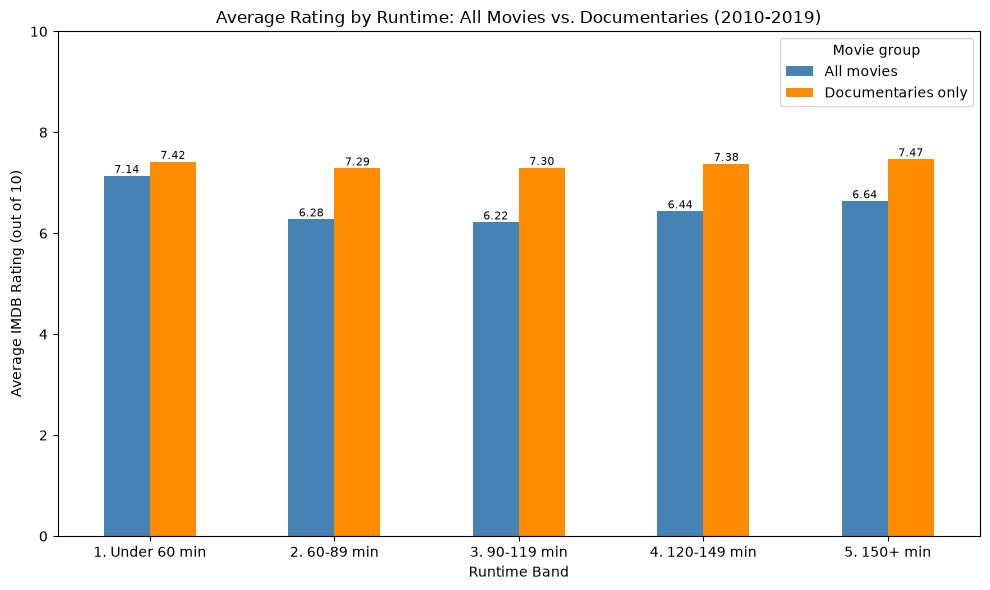

In [143]:
# Put the two average-rating columns side by side in one table
compare = pd.DataFrame({
    'All movies': runtime_all['avg_rating'].values,
    'Documentaries only': runtime_documentary['avg_rating'].values
}, index=runtime_all['runtime_band'])

ax = compare.plot(kind='bar', figsize=(10, 6), color=['steelblue', 'darkorange'])

plt.title('Average Rating by Runtime: All Movies vs. Documentaries (2010-2019)')
plt.xlabel('Runtime Band')
plt.ylabel('Average IMDB Rating (out of 10)')
plt.xticks(rotation=0)
plt.ylim(0, 10)
plt.legend(title='Movie group')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', fontsize=8)

plt.tight_layout()
plt.savefig('visual4_all_vs_documentaries.png', dpi=200, bbox_inches='tight')
plt.show()

# Business question:
Among feature-length movies(60 minutes or more), is there a runtime range that earns higher ratings, and does the pattern hold across major genres such as Drama, Comendy, Action and Horror?

Test the question by genre(feature-length only)

In [144]:
# One query builds the whole table.
# For each genre, AVG(CASE WHEN ... THEN rating END) averages the ratings
# of only the movies whose genres contain that word. Other movies are skipped.
# A movie with several genres counts in each genre it belongs to.
rating_table = pd.read_sql("""
SELECT CASE WHEN b.runtime_minutes < 90  THEN '1. 60-89 min'
            WHEN b.runtime_minutes < 120 THEN '2. 90-119 min'
            WHEN b.runtime_minutes < 150 THEN '3. 120-149 min'
            ELSE '4. 150+ min' END AS runtime_band,
       ROUND(AVG(CASE WHEN b.genres LIKE '%Drama%'  THEN r.averagerating END), 2) AS Drama,
       ROUND(AVG(CASE WHEN b.genres LIKE '%Comedy%' THEN r.averagerating END), 2) AS Comedy,
       ROUND(AVG(CASE WHEN b.genres LIKE '%Action%' THEN r.averagerating END), 2) AS Action,
       ROUND(AVG(CASE WHEN b.genres LIKE '%Horror%' THEN r.averagerating END), 2) AS Horror
FROM movie_basics b
JOIN movie_ratings r ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND b.runtime_minutes >= 60
  AND r.averagerating IS NOT NULL
GROUP BY runtime_band
ORDER BY runtime_band;
""", conn4)

# Make the runtime bands the row labels, which the chart in Cell 8 needs
rating_table = rating_table.set_index('runtime_band')
rating_table

,Drama,Comedy,Action,Horror
runtime_band,,,,
1. 60-89 min,6.34,5.99,5.49,4.71
2. 90-119 min,6.34,5.96,5.70,5.09
3. 120-149 min,6.55,6.17,6.18,5.68
4. 150+ min,6.69,6.21,6.07,5.66


A visual

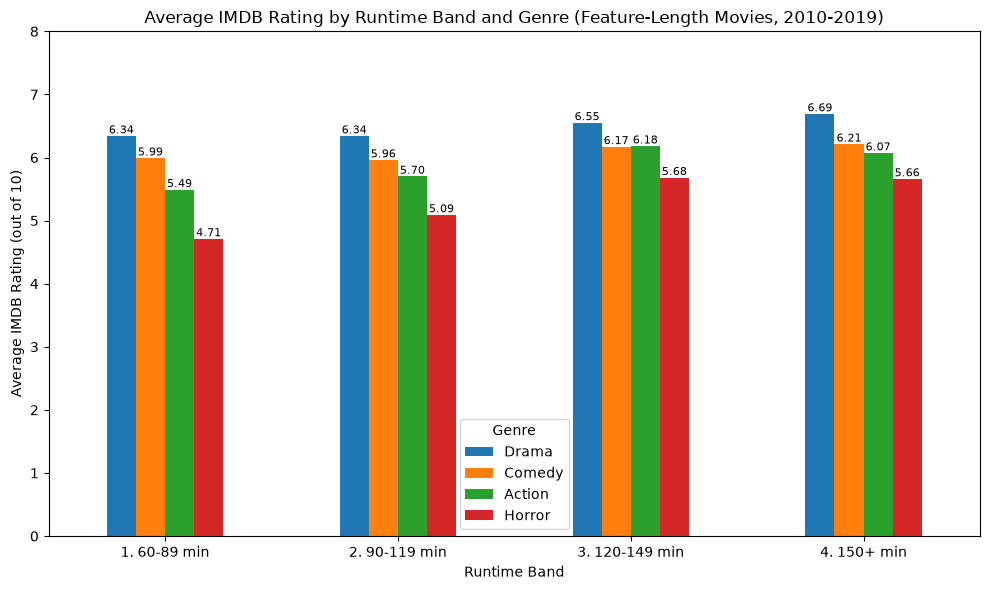

In [145]:
ax = rating_table.plot(kind='bar', figsize=(10, 6))

plt.title('Average IMDB Rating by Runtime Band and Genre (Feature-Length Movies, 2010-2019)')
plt.xlabel('Runtime Band')
plt.ylabel('Average IMDB Rating (out of 10)')
plt.xticks(rotation=0)
plt.ylim(0, 8)                       # starts at 0 so the bars are not exaggerated
plt.legend(title='Genre')

# Write the value on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', fontsize=8)

plt.tight_layout()
plt.savefig('visual5_runtime_by_genre.png', dpi=200, bbox_inches='tight')
plt.show()


Data cleaning 

In [146]:
cleaning_checks = pd.read_sql("""
SELECT
 (SELECT COUNT(*) FROM movie_basics WHERE start_year > 2019) AS years_after_2019,
 (SELECT MAX(start_year) FROM movie_basics) AS latest_year_listed,
 (SELECT COUNT(*) FROM movie_basics WHERE start_year BETWEEN 2010 AND 2019 AND runtime_minutes IS NULL) AS missing_runtime,
 (SELECT COUNT(*) FROM movie_basics WHERE start_year BETWEEN 2010 AND 2019 AND genres IS NULL) AS missing_genres,
 (SELECT MAX(runtime_minutes) FROM movie_basics WHERE start_year BETWEEN 2010 AND 2019) AS longest_runtime,
 (SELECT COUNT(*) FROM movie_basics WHERE start_year BETWEEN 2010 AND 2019 AND runtime_minutes < 10) AS runtime_under_10_min,
 (SELECT COUNT(*) FROM movie_basics WHERE start_year BETWEEN 2010 AND 2019 AND genres LIKE '%,%') AS multi_genre_rows,
 (SELECT COUNT(*) FROM movie_basics b JOIN movie_ratings r ON b.movie_id = r.movie_id
    WHERE b.start_year BETWEEN 2010 AND 2019 AND r.numvotes < 100) AS ratings_under_100_votes,
 (SELECT COUNT(*) FROM movie_basics WHERE start_year BETWEEN 2010 AND 2019 AND primary_title <> original_title) AS titles_that_differ;
""", conn4)
cleaning_checks.T

,0
years_after_2019,1063.0
latest_year_listed,2115.0
missing_runtime,30765.0
missing_genres,5359.0
longest_runtime,51420.0
runtime_under_10_min,1155.0
multi_genre_rows,59022.0
ratings_under_100_votes,45103.0
titles_that_differ,14456.0


A visual

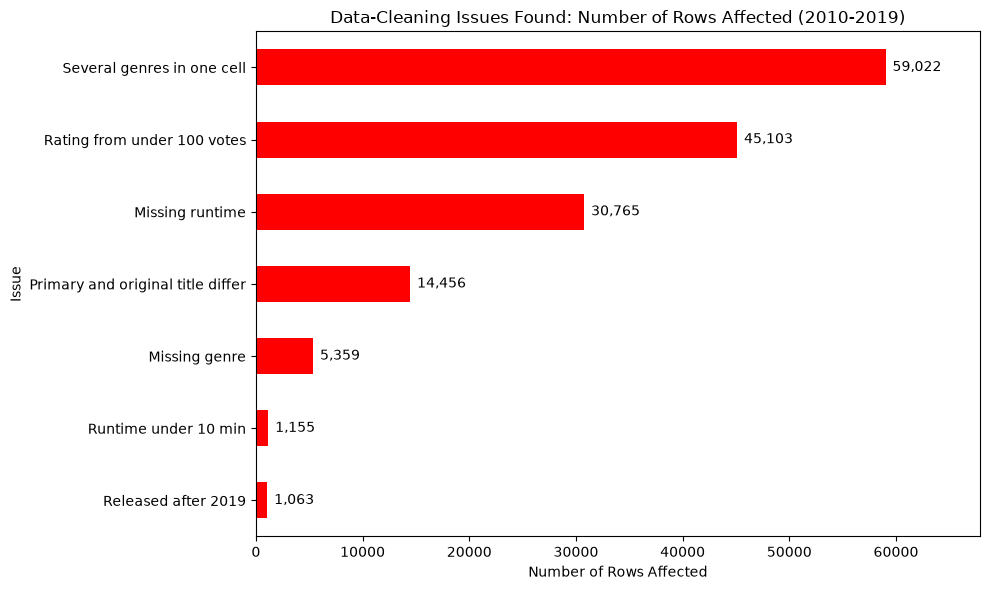

In [147]:
# Keep only the columns that are row counts, then turn them into a two-column table
counts_only = cleaning_checks.drop(columns=['latest_year_listed', 'longest_runtime'])
issues = counts_only.T.reset_index()
issues.columns = ['issue', 'rows_affected']

# Replace the column names with plain-English labels for the chart
issues['issue'] = issues['issue'].replace({
    'years_after_2019': 'Released after 2019',
    'missing_runtime': 'Missing runtime',
    'missing_genres': 'Missing genre',
    'runtime_under_10_min': 'Runtime under 10 min',
    'multi_genre_rows': 'Several genres in one cell',
    'ratings_under_100_votes': 'Rating from under 100 votes',
    'titles_that_differ': 'Primary and original title differ'
})
issues = issues.sort_values('rows_affected')

ax = issues.plot(kind='barh', x='issue', y='rows_affected',
                 legend=False, figsize=(10, 6), color='red')

plt.title('Data-Cleaning Issues Found: Number of Rows Affected (2010-2019)')
plt.xlabel('Number of Rows Affected')
plt.ylabel('Issue')

for bar in ax.patches:
    ax.annotate(f"{bar.get_width():,.0f}", (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                ha='left', va='center', xytext=(5, 0), textcoords='offset points')

ax.set_xlim(0, issues['rows_affected'].max() * 1.15)   # room for the labels

plt.tight_layout()
plt.savefig('visual6_cleaning_issues.png', dpi=200, bbox_inches='tight')
plt.show()

I found some data-cleaning tasks, but I haven't yet performed them: 

- Movies dated after 2019. They are 1,063 and according to the instructions this data is not accurate, so I would remove them.
- No runtimes or genre information. 30,765 movies have no runtime and 5,359 have no genre. I would not leave these blank, I would just have to guess.
- Odd runtimes. One movie runs 51,420 minutes, and 1,155 are under 10 minutes. These appear to be errors and I would verify and establish reasonable parameters.
- One or more genres in more than one cell. 59,022 movies have multiple genres, such as “Action,Crime,Drama”. I would divide these up so that each genre has a row and can be counted correctly.
- Ratings that have a small number of votes. Less than 100 votes means that the ratings are not reliable (45,103 ratings). I would set a minimum number of votes.
- Titles that don’t match. There are 14,456 movies that have different primary title and original title, make them consistent.

In [148]:
# closing connection
conn4.close()